In [ ]:
# JERICHON import bootstrap (shared resolver in src/project_paths.py)
from pathlib import Path
import os, sys

# Locate repository from the current working directory or its parents.
_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
for _base in list(_candidates):
    try:
        _candidates.extend(_child for _child in _base.iterdir() if _child.is_dir())
    except (OSError, PermissionError):
        pass
PROJECT_ROOT = next((p.resolve() for p in _candidates
                     if (p / "src" / "__init__.py").is_file()
                     and (p / "src" / "data" / "builders").is_dir()), None)
if PROJECT_ROOT is None:
    _env_root = os.environ.get("JERICHON_PROJECT_ROOT")
    if _env_root:
        _candidate = Path(_env_root).expanduser().resolve()
        if (_candidate / "src" / "__init__.py").is_file():
            PROJECT_ROOT = _candidate
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Не найден корень JERICHON. Откройте VS Code в папке репозитория "
        "или задайте JERICHON_PROJECT_ROOT.")
if str(PROJECT_ROOT) in sys.path:
    sys.path.remove(str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT))
from src.project_paths import bootstrap_project, find_project_root
PROJECT_ROOT = bootstrap_project(PROJECT_ROOT)


# JERICHON — SC_06: проверка Super Candles на отложенном периоде и поиск режимов

**Вопрос исследования:** дают ли аномалии Super Candles информацию о будущем поведении рынка на данных, которые не использовались для выбора кандидатов?

Тикеры: **SMLT, GAZP, SPBE, MTLR, YDEX**.

Ноутбук повторно использует причинный загрузчик и построение групповых оценок из SC_05. После этого:
1. Делит историю каждого тикера по времени на ранний исследовательский участок и поздний проверочный участок.
2. На раннем участке выбирает ограниченный набор кандидатов — не более 3 групп на тикер.
3. Фиксирует кандидатов и проверяет их на позднем участке, не подбирая их заново.
4. Проверяет три результата: вероятность значимого движения в любую сторону, увеличение будущего диапазона, вероятность режима повышенного будущего диапазона.
5. Строит интервалы неопределённости с повторной выборкой целых торговых дней и корректирует значения вероятности случайного результата на множественные проверки.
6. Сохраняет CSV после обработки каждого тикера.

**Важно:** это проверка прогностической информации, не торговый бэктест. Положительный результат не доказывает прибыльность после цены входа, комиссий и проскальзывания.

**Причинность:** используем только группы и пороги, построенные с `shift(1)` в исходном SC_05 pipeline. Целевые значения считаются исключительно по будущим барам. Проверочный период не участвует в выборе групп и порогов режима.


## 1. Настройки и ожидаемое время

Используется локальная история AlgoPack. Основной риск времени — построение 474 признаков; сам проверочный расчёт ограничен выбранными группами и векторизованными массивами. В консоли печатается прогресс по тикерам.\n

In [1]:
from pathlib import Path
import sys, inspect, warnings, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TICKERS = ["SMLT", "GAZP", "SPBE", "MTLR", "YDEX"]
DOLLAR_THRESHOLD = 10_000_000
ROLLING_WINDOW = 500
MIN_HISTORY = 100
ANOMALY_QUANTILES = (0.95, 0.99)
GROUP_QUANTILES = (0.95, 0.99)
EPISODE_GAP_BARS = 3
MAX_CONTROLS_PER_EVENT = 3
RANDOM_STATE = 17

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    # Common explicit fallback: edit this if notebook is outside the repository.
    fallback = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON")
    if (fallback / "data" / "for_ml" / "storage" / "history").exists():
        return fallback
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную в этой ячейке."
    )

PROJECT_ROOT = find_project_root()
DATA_ROOT = PROJECT_ROOT / "data"
HISTORY_ROOT = DATA_ROOT / "for_ml" / "storage" / "history"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.builders import jerichon_feature_pipeline as jfp

required_helpers = ("build_dollar_bars_from_trades", "_base", "_build_sc_features", "_choose_availability", "_attach_source")
missing = [x for x in required_helpers if not hasattr(jfp, x)]
if missing:
    raise RuntimeError(f"В установленном jerichon_feature_pipeline.py отсутствуют helpers: {missing}")

print("Project root:", PROJECT_ROOT)
print("History root:", HISTORY_ROOT)
print("Pipeline:", Path(inspect.getfile(jfp)).resolve())
print("Tickers:", TICKERS)
print("Dollar threshold:", f"{DOLLAR_THRESHOLD:,}")


Project root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON
History root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history
Pipeline: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Tickers: ['SMLT', 'GAZP', 'SPBE', 'MTLR', 'YDEX']
Dollar threshold: 10,000,000


## 2. Построение причинного набора

Повторно используем проверенную загрузку и существующий feature pipeline; контракт 73 + 401 = 474 проверяется до анализа.

In [2]:
def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")

def load_local_history(history_root, ticker):
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    dates = available_dates(history_root, ticker)
    if not dates:
        raise FileNotFoundError(f"{ticker}: не найдены локальные сохранённые даты в {history_root}")
    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING {ticker}: не прочитан {p}: {e}")
        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING {ticker}: не прочитан {p}: {e}")
    out = {k: (pd.concat(v, ignore_index=True) if v else pd.DataFrame()) for k, v in frames.items()}
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing:
        raise RuntimeError(f"{ticker}: отсутствуют локальные источники {missing}; API не вызывается.")
    return out, dates

def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось однозначно сопоставить {source}; доступны: {list(frames)}")

def build_ticker_dataset(ticker):
    data, saved_dates = load_local_history(HISTORY_ROOT, ticker)
    bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
    if bars is None or bars.empty:
        raise RuntimeError(f"{ticker}: Dollar Bar builder вернул пустой результат.")
    if "bar_ts" not in bars.columns:
        if "close_time" not in bars.columns:
            raise RuntimeError(f"{ticker}: в bars нет bar_ts/close_time; columns={list(bars.columns)}")
        bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
    else:
        bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
    bars = bars.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

    # The pipeline creates many derived columns by repeated assignment. Its
    # fragmentation PerformanceWarnings are known and are summarized once,
    # rather than flooding the notebook output.
    perf_warning_count = 0
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", pd.errors.PerformanceWarning)
        base = jfp._base(bars.copy())
    perf_warning_count += sum(issubclass(w.category, pd.errors.PerformanceWarning) for w in captured)
    if isinstance(base, tuple):
        base = base[0]
    if not isinstance(base, pd.DataFrame):
        raise TypeError(f"{ticker}: _base не вернул DataFrame")
    if "bar_ts" not in base.columns:
        if "close_time" in base.columns:
            base = base.rename(columns={"close_time": "bar_ts"})
        elif isinstance(base.index, pd.DatetimeIndex):
            base = base.reset_index().rename(columns={base.index.name or "index": "bar_ts"})
        elif "ts" in base.columns:
            base = base.rename(columns={"ts": "bar_ts"})
        else:
            raise RuntimeError(f"{ticker}: не найден временной ключ в base features")
    base["bar_ts"] = pd.to_datetime(base["bar_ts"], errors="coerce", utc=True)
    base = base.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last")

    bars_sc = bars.copy()
    if "ts" not in bars_sc.columns:
        bars_sc["ts"] = bars_sc["bar_ts"]
    if "CLOSE" not in bars_sc.columns:
        close_col = next((c for c in bars_sc.columns if str(c).lower() == "close"), None)
        if close_col is None:
            raise RuntimeError(f"{ticker}: нет CLOSE/close в Dollar Bars")
        bars_sc["CLOSE"] = bars_sc[close_col]
    bars_sc["ts"] = pd.to_datetime(bars_sc["ts"], errors="coerce", utc=True)
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", pd.errors.PerformanceWarning)
        sc_result = jfp._build_sc_features(
            data,
            bars_sc.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True),
        )
    perf_warning_count += sum(issubclass(w.category, pd.errors.PerformanceWarning) for w in captured)
    feature_frames = sc_result[0] if isinstance(sc_result, tuple) else sc_result
    if not isinstance(feature_frames, dict):
        raise TypeError(f"{ticker}: _build_sc_features должен вернуть dict")

    causal = bars.copy()
    for source in ("tradestats", "obstats", "orderstats"):
        # Validate source availability using the pipeline's established helper.
        checked = jfp._choose_availability(data[source].copy(), source)
        if isinstance(checked, tuple):
            checked = checked[0]
        if checked is None or len(checked) == 0:
            raise RuntimeError(f"{ticker}: availability validation вернула пустой {source}")
        ff = resolve_feature_frame(source, feature_frames)
        attached = jfp._attach_source(causal, ff, data[source], source)
        if isinstance(attached, pd.DataFrame):
            causal = attached

    base_cols_raw = [c for c in base.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base[c])]
    if len(base_cols_raw) != 73:
        raise RuntimeError(f"{ticker}: ожидалось 73 base features, найдено {len(base_cols_raw)}")
    base_join = base[["bar_ts"] + base_cols_raw].copy()
    base_join = base_join.rename(columns={c: f"base__{c}" for c in base_cols_raw})
    causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
    causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

    provenance = [c for c in causal.columns if c.endswith("__event_ts") or c.endswith("__available_at")]
    prefixes = ("tradestats__", "obstats__", "orderstats__")
    sc_cols = [c for c in causal.columns if c.startswith(prefixes) and c not in provenance and pd.api.types.is_numeric_dtype(causal[c])]
    # IMPORTANT: test the dtype of the SERIES causal[c], not the column-name
    # string c. Testing c silently dropped all 73 base features.
    base_feature_cols = [
        c for c in causal.columns
        if c.startswith("base__") and pd.api.types.is_numeric_dtype(causal[c])
    ]
    feature_cols = base_feature_cols + sc_cols

    # Validate each block separately so a mismatch reports exactly which block
    # is absent; don't silently skip a ticker or hide the root cause.
    if len(base_feature_cols) != len(base_cols_raw):
        raise RuntimeError(
            f"{ticker}: после merge сохранилось {len(base_feature_cols)} из "
            f"{len(base_cols_raw)} базовых признаков"
        )
    if not sc_cols:
        raise RuntimeError(
            f"{ticker}: после causal attach не найдено числовых SC-признаков. "
            f"Колонки итогового frame: {list(causal.columns)}"
        )
    if len(feature_cols) != 474:
        raise RuntimeError(
            f"{ticker}: состав признаков отличается от ожидаемого: "
            f"base={len(base_feature_cols)} (ожидалось 73), "
            f"SC={len(sc_cols)} (ожидалось 401), total={len(feature_cols)}. "
            "Тикер не будет молча отброшен: проверь названия колонок в pipeline."
        )
    causal = causal.sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)
    # Keep bar fields for forward path analysis, plus features and provenance.
    if perf_warning_count:
        print(f"{ticker}: подавлено предупреждений о фрагментации DataFrame: {perf_warning_count}")
    return {
        "ticker": ticker, "data": data, "dates": saved_dates, "bars": bars,
        "dataset": causal, "feature_cols": feature_cols, "base_cols": base_feature_cols,
        "sc_cols": sc_cols, "provenance": provenance,
    }

datasets = {}
load_rows = []
load_errors = []
for ticker in TICKERS:
    try:
        obj = build_ticker_dataset(ticker)
        datasets[ticker] = obj
        load_rows.append({
            "ticker": ticker, "saved_dates": len(obj["dates"]),
            "date_start": obj["dates"][0], "date_end": obj["dates"][-1],
            "dollar_bars": len(obj["bars"]), "base_features": len(obj["base_cols"]),
            "supercandle_features": len(obj["sc_cols"]), "features_total": len(obj["feature_cols"]),
        })
        print(
            f"OK {ticker}: bars={len(obj['bars']):,}; "
            f"base={len(obj['base_cols'])}; SC={len(obj['sc_cols'])}; "
            f"dates={obj['dates'][0]} → {obj['dates'][-1]}"
        )
    except Exception as e:
        message = f"{ticker}: {type(e).__name__}: {e}"
        load_errors.append(message)
        print(f"ERROR {message}")
display(pd.DataFrame(load_rows))
if load_errors:
    print("\nОшибки загрузки (кратко):")
    for message in load_errors:
        print(" -", message)
if not datasets:
    raise RuntimeError(
        "Не удалось подготовить данные ни для одного тикера. Причины выше: "
        + " | ".join(load_errors)
    )


SMLT: подавлено предупреждений о фрагментации DataFrame: 74
OK SMLT: bars=2,907; base=73; SC=401; dates=2026-09-25 → 2026-10-23
GAZP: подавлено предупреждений о фрагментации DataFrame: 74
OK GAZP: bars=11,566; base=73; SC=401; dates=2026-09-24 → 2026-10-23
SPBE: подавлено предупреждений о фрагментации DataFrame: 74
OK SPBE: bars=2,503; base=73; SC=401; dates=2026-08-28 → 2026-10-23
MTLR: подавлено предупреждений о фрагментации DataFrame: 74
OK MTLR: bars=1,547; base=73; SC=401; dates=2026-08-28 → 2026-10-23
YDEX: подавлено предупреждений о фрагментации DataFrame: 74
OK YDEX: bars=10,737; base=73; SC=401; dates=2026-08-28 → 2026-10-23


,ticker,saved_dates,date_start,date_end,dollar_bars,base_features,supercandle_features,features_total
0,SMLT,16,2026-09-25,2026-10-23,2907,73,401,474
1,GAZP,17,2026-09-24,2026-10-23,11566,73,401,474
2,SPBE,34,2026-08-28,2026-10-23,2503,73,401,474
3,MTLR,35,2026-08-28,2026-10-23,1547,73,401,474
4,YDEX,34,2026-08-28,2026-10-23,10737,73,401,474


## 3. Свернуть 401 столбец в корневые метрики и смысловые семьи

Например, `x`, `x_ma3`, `x_z12`, `x_chg`, `x_ret` относятся к одному корневому сигналу. Семьи по названиям эвристические и нужны только для первого анализа.

In [3]:
import math, re
from collections import defaultdict

TRANSFORM_RE = re.compile(r"_(?:ma\d+|z\d+|chg|ret)$", re.IGNORECASE)
def root_feature_name(col):
    source, metric = col.split("__", 1)
    while True:
        new_metric = TRANSFORM_RE.sub("", metric)
        if new_metric == metric: break
        metric = new_metric
    return f"{source}__{metric}"
def transform_complexity(col):
    return len(TRANSFORM_RE.findall(col.split("__", 1)[1]))
def semantic_family(root_col):
    m = root_col.split("__", 1)[1].lower()
    if any(k in m for k in ("imb", "imbalance", "bid", "ask", "buy", "sell", "aggress", "b_s", "share")): return "imbalance_pressure"
    if any(k in m for k in ("spread", "liquidity", "cost", "vwap", "px_", "price", "mid", "microprice", "bps")): return "liquidity_price"
    if any(k in m for k in ("volume", "value", "turnover", "trade", "count", "qty", "notional", "amount")): return "activity_volume"
    if any(k in m for k in ("order", "depth", "level", "queue", "cancel", "add", "modify")): return "orders_depth"
    return "other"

# Inventory is shared across tickers; the loader separately validates 73 + 401 = 474 per ticker.
all_sc_cols = datasets[next(iter(datasets))]["sc_cols"]
root_members = defaultdict(list)
for col in all_sc_cols: root_members[root_feature_name(col)].append(col)
root_rows = []
for root, members in sorted(root_members.items()):
    source = root.split("__", 1)[0]
    chosen = root if root in members else sorted(members, key=lambda c:(transform_complexity(c),len(c),c))[0]
    root_rows.append({"root":root,"source":source,"family":semantic_family(root),"chosen_feature":chosen,"variants":len(members),"is_raw_root":chosen==root})
root_map = pd.DataFrame(root_rows)
print(f"401 SC columns collapsed into {root_map.root.nunique()} root metrics")
print("Root metrics by source/family:")
print(root_map.groupby(["source","family"]).size().rename("roots").to_string())
print("\nTransformation variants per root:")
print(root_map.variants.value_counts().sort_index().rename_axis("variants").to_string())


401 SC columns collapsed into 51 root metrics
Root metrics by source/family:
source      family            
obstats     activity_volume        2
            imbalance_pressure     7
            liquidity_price        7
orderstats  activity_volume        4
            imbalance_pressure    13
            liquidity_price        2
            orders_depth           2
tradestats  activity_volume        2
            imbalance_pressure    10
            other                  2

Transformation variants per root:
variants
1     16
11    35


## 4. Причинные групповые scores

Для каждого корневого признака отклонение от rolling median нормируется на прошлый 95-й перцентиль отклонений. Все окна сдвинуты на один бар. Затем групповой score — среднее верхних 20% root-scores; событие — превышение прошлого 95-го или 99-го перцентиля группового score.

In [4]:
def find_ohlc_columns(bars):
    lower = {str(c).lower():c for c in bars.columns}
    out = {k:next((lower[x] for x in names if x in lower),None) for k,names in {
        "open":("open","o"),"high":("high","h"),"low":("low","l"),"close":("close","c")}.items()}
    missing = [k for k,v in out.items() if v is None]
    if missing: raise RuntimeError(f"OHLC columns missing {missing}; columns={list(bars.columns)}")
    return out

def root_scores_for_ticker(obj):
    ds = obj["dataset"].reset_index(drop=True)
    out = {}
    for _, r in root_map.iterrows():
        col = r["chosen_feature"]
        if col not in ds: continue
        x = pd.to_numeric(ds[col],errors="coerce").replace([np.inf,-np.inf],np.nan)
        med = x.rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).median().shift(1)
        dev = (x-med).abs()
        scale = dev.rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).quantile(.95).shift(1)
        out[r["root"]] = dev / scale.where(scale>0)
    return pd.DataFrame(out)

def top_fraction_mean(frame, fraction=.20):
    if frame.shape[1]==0: return pd.Series(np.nan,index=frame.index)
    a=frame.to_numpy(dtype=float).copy(); a[~np.isfinite(a)]=-np.inf; a.sort(axis=1)
    k=max(1,int(math.ceil(frame.shape[1]*fraction))); top=a[:,-k:]
    ok=np.isfinite(top); sums=np.where(ok,top,0).sum(axis=1); counts=ok.sum(axis=1)
    return pd.Series(np.divide(sums,counts,out=np.full(len(frame),np.nan),where=counts>0),index=frame.index)

def group_scores_for_ticker(obj):
    roots=root_scores_for_ticker(obj); meta=root_map.set_index("root"); groups={}
    for source in ("tradestats","obstats","orderstats"):
        cols=[c for c in roots if meta.loc[c,"source"]==source]
        if cols: groups[f"source::{source}"]=top_fraction_mean(roots[cols])
    for (source,family),part in root_map.groupby(["source","family"]):
        cols=[c for c in part.root.tolist() if c in roots]
        if len(cols)>=2: groups[f"source_family::{source}::{family}"]=top_fraction_mean(roots[cols])
    scores=pd.DataFrame(groups)
    flags={}; thresholds={}
    for col in scores:
        for q in GROUP_QUANTILES:
            th=scores[col].rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).quantile(q).shift(1)
            thresholds[(col,q)]=th; flags[(col,q)]=scores[col].gt(th)&th.notna()&scores[col].notna()
    return scores,thresholds,flags

group_results={}
for ticker,obj in datasets.items():
    scores,thresholds,flags=group_scores_for_ticker(obj)
    group_results[ticker]={"scores":scores,"thresholds":thresholds,"flags":flags}
    print(f"{ticker}: {scores.shape[1]} source/family groups; {len(scores):,} bars")


SMLT: 13 source/family groups; 2,907 bars
GAZP: 13 source/family groups; 11,566 bars
SPBE: 13 source/family groups; 2,503 bars
MTLR: 13 source/family groups; 1,547 bars
YDEX: 13 source/family groups; 10,737 bars


## 2. Дизайн проверки

- **Ранний период (60%)** — только для выбора до трёх групп-кандидатов на тикер.
- **Поздний период (40%)** — проверка заранее зафиксированных кандидатов.
- Событие: аномальный групповой показатель выше исторического 95-го или 99-го процентиля, рассчитанного без текущего бара.
- Цели: движение от закрытия сигнального бара в любую сторону на 0,5% за 3/5/10 баров; будущий диапазон; режим повышенного диапазона.
- Контроль: бары позднего периода, на которых конкретная группа не подала сигнал.
- Неопределённость: повторно выбираем целые торговые дни, а не отдельные бары. Это частично учитывает зависимость наблюдений внутри дня.
- Поправка Бенджамини—Хохберга (BH) снижает риск ложных находок при множественных проверках.

**Ограничение:** при короткой истории и малом числе дней интервалы будут широкими. Это корректный результат, а не повод ослаблять критерии после просмотра теста.


In [6]:
# SC_06: быстрый отложенный тест. Код не перебирает все группы на проверочном участке.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, math, time

OUTPUT_DIR = Path("research/supercandles/mark_6/results"); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_CSV = OUTPUT_DIR / "SC_06_holdout_regime_results.csv"
TRAIN_FRACTION = 0.60
CANDIDATES_PER_TICKER = 3
TEST_QUANTILES = (0.95, 0.99)
TEST_HORIZONS = (3, 5, 10)
MOVE_THRESHOLD_PCT = 0.50
BOOTSTRAP_REPS = 500
RANDOM_SEED = 20261023

def get_times_and_ohlc(obj):
    ds = obj["dataset"].reset_index(drop=True)
    bars = obj["bars"].reset_index(drop=True)
    # Данные dataset и bars должны быть выровнены тем же pipeline; если число строк не совпало,
    # безопасно выравниваем по bar_ts, а не по случайному индексу.
    tcol = "bar_ts" if "bar_ts" in ds.columns else "close_time"
    bcol = "bar_ts" if "bar_ts" in bars.columns else "close_time"
    if tcol in ds.columns and bcol in bars.columns:
        left = ds[[tcol]].copy()
        right = bars.copy()
        if tcol != bcol:
            right = right.rename(columns={bcol:tcol})
        merged = left.merge(right, on=tcol, how="left", suffixes=("", "_bar"), validate="one_to_one")
        if len(merged) == len(ds):
            bars = merged
    cols = find_ohlc_columns(bars)
    times = pd.to_datetime(ds[tcol], errors="coerce", utc=True)
    close = pd.to_numeric(bars[cols["close"]], errors="coerce").to_numpy(float)
    high = pd.to_numeric(bars[cols["high"]], errors="coerce").to_numpy(float)
    low = pd.to_numeric(bars[cols["low"]], errors="coerce").to_numpy(float)
    return ds, times, close, high, low

def bh_adjust(pvals):
    p = np.asarray(pvals, float)
    out = np.full(len(p), np.nan)
    good = np.isfinite(p)
    if not good.any(): return out
    pv = p[good]; order = np.argsort(pv); ranked = pv[order]
    q = ranked * len(ranked) / np.arange(1, len(ranked)+1)
    q = np.minimum.accumulate(q[::-1])[::-1].clip(0,1)
    temp = np.empty_like(q); temp[order] = q
    out[np.where(good)[0]] = temp
    return out

def future_targets(close, high, low, max_h):
    """Векторно считает цели по следующим барам, без цикла по каждой строке."""
    n=len(close)
    fut_range=np.full((max_h,n),np.nan)
    either=np.full((max_h,n),np.nan)
    continuation=np.full((max_h,n),np.nan)
    prev_ret=np.full(n,np.nan)
    prev_ret[1:]=close[1:]/close[:-1]-1
    # Для каждого горизонта окно начинается со следующего бара.
    from numpy.lib.stride_tricks import sliding_window_view
    for h in range(1,max_h+1):
        if n <= h: continue
        wh=sliding_window_view(high[1:],h)
        wl=sliding_window_view(low[1:],h)
        count=n-h
        maxh=np.nanmax(wh[:count],axis=1)
        minl=np.nanmin(wl[:count],axis=1)
        base=close[:count]
        valid=np.isfinite(base)&(base>0)&np.isfinite(maxh)&np.isfinite(minl)
        fr=np.full(count,np.nan); ev=np.full(count,np.nan)
        fr[valid]=(maxh[valid]-minl[valid])/base[valid]*100
        up=np.full(count,np.nan); dn=np.full(count,np.nan)
        up[valid]=(maxh[valid]/base[valid]-1)*100
        dn[valid]=(1-minl[valid]/base[valid])*100
        ev[valid]=(np.maximum(up[valid],dn[valid])>=MOVE_THRESHOLD_PCT).astype(float)
        fut_range[h-1,:count]=fr
        either[h-1,:count]=ev
        endret=close[h:h+count]/base-1
        pv=prev_ret[:count]
        ok=valid&np.isfinite(pv)&(pv!=0)&np.isfinite(endret)
        continuation[h-1,:count][ok]=(np.sign(endret[ok])==np.sign(pv[ok])).astype(float)
    return fut_range,either,continuation

def day_cluster_bootstrap_delta(event, target, day_ids, reps=500, seed=1):
    valid = event & np.isfinite(target)
    control = (~event) & np.isfinite(target)
    if valid.sum() < 8 or control.sum() < 8:
        return np.nan, np.nan, np.nan, np.nan, int(valid.sum()), int(control.sum())
    delta = float(np.nanmean(target[valid]) - np.nanmean(target[control]))
    days = pd.unique(day_ids[pd.notna(day_ids)])
    if len(days) < 4: return delta, np.nan, np.nan, np.nan, int(valid.sum()), int(control.sum())
    rng = np.random.default_rng(seed)
    boots = []
    # Перевыбираем дни с возвращением; сохраняем внутри дня все наблюдения.
    for _ in range(reps):
        picked = rng.choice(days, size=len(days), replace=True)
        e_vals=[]; c_vals=[]
        for d in picked:
            m = day_ids == d
            em = m & event & np.isfinite(target)
            cm = m & (~event) & np.isfinite(target)
            if em.any(): e_vals.extend(target[em].tolist())
            if cm.any(): c_vals.extend(target[cm].tolist())
        if e_vals and c_vals:
            boots.append(np.mean(e_vals)-np.mean(c_vals))
    if len(boots) < 50: return delta, np.nan, np.nan, np.nan, int(valid.sum()), int(control.sum())
    lo, hi = np.quantile(boots, [0.025,0.975])
    # Двусторонняя bootstrap-оценка p-value относительно нуля.
    b = np.asarray(boots)
    pval = min(1.0, 2 * min((np.sum(b <= 0)+1)/(len(b)+1), (np.sum(b >= 0)+1)/(len(b)+1)))
    return delta, float(lo), float(hi), float(pval), int(valid.sum()), int(control.sum())

def choose_candidates(ticker, obj, cut):
    ds, times, close, high, low = get_times_and_ohlc(obj)
    scores, thresholds, flags = group_results[ticker]["scores"], group_results[ticker]["thresholds"], group_results[ticker]["flags"]
    n = min(len(ds), len(scores), len(close))
    cut = int(n * TRAIN_FRACTION)
    max_h = max(TEST_HORIZONS)
    fr, mv, cont = future_targets(close[:n], high[:n], low[:n], max_h)
    train_idx = np.arange(n) < cut
    candidates=[]
    for group in scores.columns:
        best = None
        for q in TEST_QUANTILES:
            ev = flags.get((group,q))
            if ev is None: continue
            ev = ev.iloc[:n].fillna(False).to_numpy(bool) & train_idx
            # Селекция только на раннем участке: движение 0,5% за 5/10 баров и диапазон.
            for h in (5,10):
                y = mv[h-1,:n]
                ok = ev & np.isfinite(y)
                ctrl = (~ev) & train_idx & np.isfinite(y)
                if ok.sum() < 8 or ctrl.sum() < 20: continue
                delta_move = float(y[ok].mean()-y[ctrl].mean())
                rr = fr[h-1,:n]
                rr_ok = ev & np.isfinite(rr); rr_ctrl = (~ev) & train_idx & np.isfinite(rr)
                delta_range = float(np.nanmedian(rr[rr_ok])-np.nanmedian(rr[rr_ctrl])) if rr_ok.sum()>=8 and rr_ctrl.sum()>=20 else 0.0
                # Балл — ранжирование кандидатов только внутри обучающего периода.
                score = delta_move + 0.10 * delta_range
                row={"тикер":ticker,"группа":group,"квантиль":q,"оценка_на_раннем_периоде":score,
                     "прирост_вероятности_движения_ранний_п.п.":100*delta_move,
                     "разница_медианного_диапазона_ранняя_п.п.":delta_range,
                     "событий_ранний":int(ok.sum()),"горизонт_отбора":h}
                if best is None or score > best["оценка_на_раннем_периоде"]: best=row
        if best is not None: candidates.append(best)
    candidates.sort(key=lambda x:x["оценка_на_раннем_периоде"], reverse=True)
    return candidates[:CANDIDATES_PER_TICKER]

all_results=[]
candidate_rows=[]
summary_rows=[]
start_all=time.time()
for ticker, obj in datasets.items():
    t0=time.time()
    print(f"\n[{ticker}] Подготовка целей и выбор кандидатов...")
    ds, times, close, high, low = get_times_and_ohlc(obj)
    scores, thresholds, flags = group_results[ticker]["scores"], group_results[ticker]["thresholds"], group_results[ticker]["flags"]
    n=min(len(ds),len(scores),len(close))
    cut=int(n*TRAIN_FRACTION)
    # Торговый день по московскому времени; для bootstrap повторно выбираются целые дни.
    day_ids=times.iloc[:n].dt.tz_convert("Europe/Moscow").dt.strftime("%Y-%m-%d").to_numpy()
    fut_range, move_targets, continuation = future_targets(close[:n],high[:n],low[:n],max(TEST_HORIZONS))
    candidates=choose_candidates(ticker,obj,cut)
    for c in candidates:
        candidate_rows.append(c)
    if not candidates:
        print(f"[{ticker}] Нет кандидатов с минимальным числом событий; тикер сохранён как диагностический.")
        continue
    test_mask=np.arange(n)>=cut
    for c in candidates:
        group,q=c["группа"],c["квантиль"]
        event=flags[(group,q)].iloc[:n].fillna(False).to_numpy(bool) & test_mask
        # Для теста используем только бары после разделения и исключаем последние бары без будущего окна.
        for h in TEST_HORIZONS:
            valid_idx = np.arange(n) < n-h
            test_valid=test_mask & valid_idx
            ev=event & test_valid
            # Сдвиг целевых массивов на h-1: target рассчитан с сигнального бара i на i+1..i+h.
            for metric, target, unit in [
                ("движение_в_любую_сторону_не_менее_0.5_pct",move_targets[h-1], "вероятность"),
                ("будущий_диапазон_pct",fut_range[h-1], "диапазон"),
                ("продолжение_предыдущего_направления",continuation[h-1], "вероятность")]:
                delta,lo,hi,pval,ne,nc=day_cluster_bootstrap_delta(ev,target,day_ids,BOOTSTRAP_REPS,RANDOM_SEED+len(all_results))
                if metric=="будущий_диапазон_pct":
                    base=float(np.nanmedian(target[(~ev)&test_valid&np.isfinite(target)])) if np.any((~ev)&test_valid&np.isfinite(target)) else np.nan
                    evt=float(np.nanmedian(target[ev&np.isfinite(target)])) if np.any(ev&np.isfinite(target)) else np.nan
                    effect=delta  # разница средних диапазонов, в процентных пунктах диапазона
                    effect_pct=100*(evt/base-1) if np.isfinite(base) and base>0 and np.isfinite(evt) else np.nan
                    ci_lo,ci_hi=lo,hi
                else:
                    effect=100*delta
                    effect_pct=np.nan
                    ci_lo,ci_hi=100*lo,100*hi
                all_results.append({
                    "тикер":ticker,"группа":group,"квантиль":q,"горизонт_баров":h,
                    "показатель":metric,"событий_проверка":ne,"контролей_проверка":nc,
                    "эффект_событие_минус_контроль":effect,
                    "интервал_95_нижний":ci_lo,
                    "интервал_95_верхний":ci_hi,
                    "отношение_медианных_диапазонов_pct":effect_pct,
                    "p_до_поправки":pval,
                    "оценка_раннего_периода":c["оценка_на_раннем_периоде"],
                    "примечание":"проверочный период; интервалы по повторной выборке торговых дней"
                })
    # Сохраняем промежуточный CSV после каждого тикера.
    temp=pd.DataFrame(all_results)
    if not temp.empty:
        temp["q_после_BH"]=bh_adjust(temp["p_до_поправки"].to_numpy())
        temp["значимо_после_BH_5pct"]=temp["q_после_BH"]<0.05
        temp.to_csv(OUTPUT_CSV,index=False,encoding="utf-8-sig")
    print(f"[{ticker}] Кандидатов={len(candidates)}; строк проверки накоплено={len(all_results)}; время={time.time()-t0:.1f} сек.")
# Финальный CSV + файл выбора кандидатов.
results_df=pd.DataFrame(all_results)
if not results_df.empty:
    results_df["q_после_BH"]=bh_adjust(results_df["p_до_поправки"].to_numpy())
    results_df["значимо_после_BH_5pct"]=results_df["q_после_BH"]<0.05
    results_df.to_csv(OUTPUT_CSV,index=False,encoding="utf-8-sig")
candidate_df=pd.DataFrame(candidate_rows)
candidate_df.to_csv(OUTPUT_DIR/"SC_06_candidates_selected_on_early_period.csv",index=False,encoding="utf-8-sig")
print(f"\nГотово за {time.time()-start_all:.1f} сек. CSV: {OUTPUT_CSV.resolve()}")
display(results_df.head(20))



[SMLT] Подготовка целей и выбор кандидатов...
[SMLT] Кандидатов=3; строк проверки накоплено=27; время=16.3 сек.

[GAZP] Подготовка целей и выбор кандидатов...
[GAZP] Кандидатов=3; строк проверки накоплено=54; время=54.6 сек.

[SPBE] Подготовка целей и выбор кандидатов...
[SPBE] Кандидатов=3; строк проверки накоплено=81; время=26.9 сек.

[MTLR] Подготовка целей и выбор кандидатов...
[MTLR] Кандидатов=3; строк проверки накоплено=108; время=21.3 сек.

[YDEX] Подготовка целей и выбор кандидатов...
[YDEX] Кандидатов=3; строк проверки накоплено=135; время=90.6 сек.

Готово за 209.7 сек. CSV: C:\Users\Сергей Кравцов\SC_06_holdout_regime_results.csv


,тикер,группа,квантиль,горизонт_баров,показатель,событий_проверка,контролей_проверка,эффект_событие_минус_контроль,интервал_95_нижний,интервал_95_верхний,отношение_медианных_диапазонов_pct,p_до_поправки,оценка_раннего_периода,примечание,q_после_BH,значимо_после_BH_5pct
0,SMLT,source_family::orderstats::activity_volume,0.99,3,движение_в_любую_сторону_не_менее_0.5_pct,20,2884,15.797503,-5.033773,33.099236,NaN,0.147705,0.301124,проверочный период; интервалы по повторной выб...,0.312188,False
1,SMLT,source_family::orderstats::activity_volume,0.99,3,будущий_диапазон_pct,20,2884,0.079346,-0.007995,0.186986,1.504388,0.095808,0.301124,проверочный период; интервалы по повторной выб...,0.226915,False
2,SMLT,source_family::orderstats::activity_volume,0.99,3,продолжение_предыдущего_направления,18,2502,2.078337,-20.246887,23.661116,NaN,0.850299,0.301124,проверочный период; интервалы по повторной выб...,0.934421,False
3,SMLT,source_family::orderstats::activity_volume,0.99,5,движение_в_любую_сторону_не_менее_0.5_pct,20,2882,18.348369,0.244036,30.330408,NaN,0.043912,0.301124,проверочный период; интервалы по повторной выб...,0.148204,False
4,SMLT,source_family::orderstats::activity_volume,0.99,5,будущий_диапазон_pct,20,2882,0.199549,-0.042757,0.565073,8.709379,0.143713,0.301124,проверочный период; интервалы по повторной выб...,0.312188,False
5,SMLT,source_family::orderstats::activity_volume,0.99,5,продолжение_предыдущего_направления,18,2500,6.915556,-16.761083,22.440397,NaN,0.514970,0.301124,проверочный период; интервалы по повторной выб...,0.724177,False
6,SMLT,source_family::orderstats::activity_volume,0.99,10,движение_в_любую_сторону_не_менее_0.5_pct,20,2877,5.839416,4.099657,7.345423,NaN,0.003992,0.301124,проверочный период; интервалы по повторной выб...,0.021771,True
7,SMLT,source_family::orderstats::activity_volume,0.99,10,будущий_диапазон_pct,20,2877,0.240739,-0.078519,0.859004,13.474679,0.215569,0.301124,проверочный период; интервалы по повторной выб...,0.421765,False
8,SMLT,source_family::orderstats::activity_volume,0.99,10,продолжение_предыдущего_направления,18,2496,1.322115,-21.344190,19.517836,NaN,0.858283,0.301124,проверочный период; интервалы по повторной выб...,0.934421,False
9,SMLT,source_family::tradestats::imbalance_pressure,0.99,3,движение_в_любую_сторону_не_менее_0.5_pct,33,2871,26.750261,0.126210,48.280127,NaN,0.056000,0.247608,проверочный период; интервалы по повторной выб...,0.175325,False


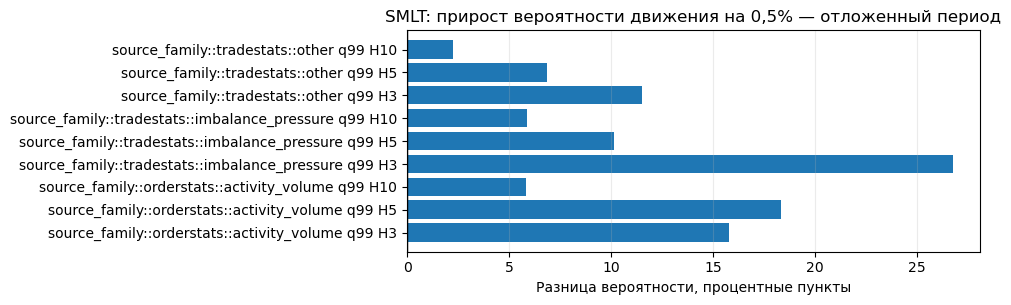

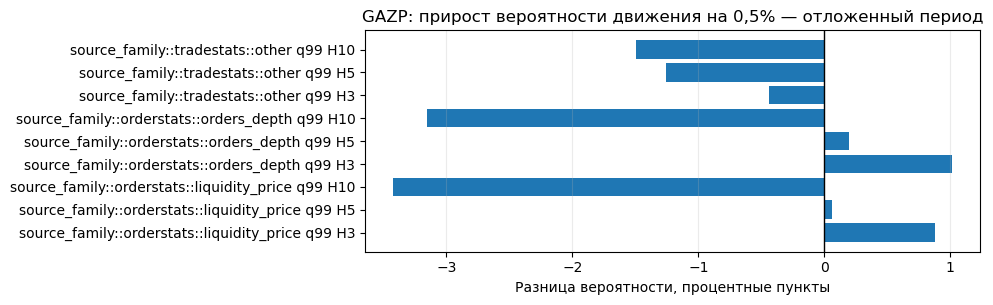

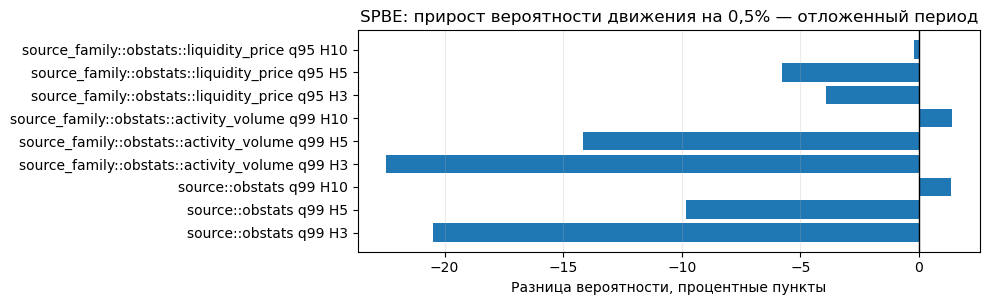

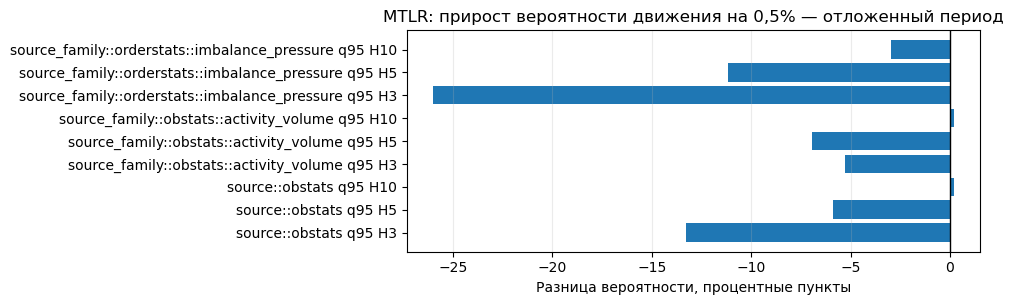

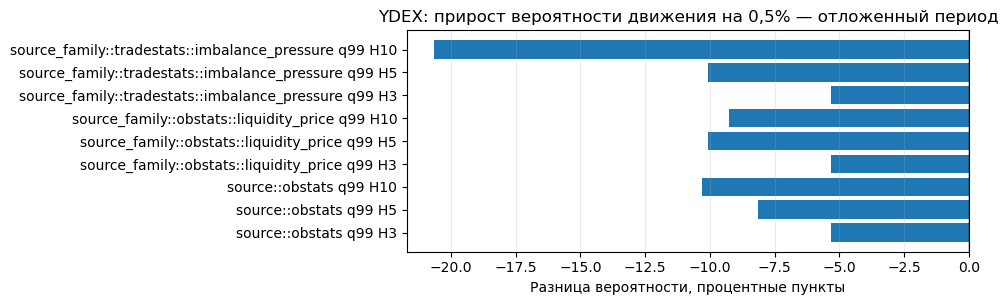

,тикер,группа,квантиль,горизонт_баров,показатель,событий_проверка,контролей_проверка,эффект_событие_минус_контроль,интервал_95_нижний,интервал_95_верхний,отношение_медианных_диапазонов_pct,p_до_поправки,оценка_раннего_периода,примечание,q_после_BH,значимо_после_BH_5pct
41,GAZP,source_family::tradestats::other,0.99,5,продолжение_предыдущего_направления,39,10522,19.392335,6.059728,34.254028,NaN,0.004016,0.104220,проверочный период; интервалы по повторной выб...,0.021771,True
125,YDEX,source_family::obstats::liquidity_price,0.99,10,продолжение_предыдущего_направления,91,9616,9.947249,4.772470,34.711078,NaN,0.003992,0.188107,проверочный период; интервалы по повторной выб...,0.021771,True
15,SMLT,source_family::tradestats::imbalance_pressure,0.99,10,движение_в_любую_сторону_не_менее_0.5_pct,33,2864,5.865922,4.314324,7.667836,NaN,0.003992,0.247608,проверочный период; интервалы по повторной выб...,0.021771,True
6,SMLT,source_family::orderstats::activity_volume,0.99,10,движение_в_любую_сторону_не_менее_0.5_pct,20,2877,5.839416,4.099657,7.345423,NaN,0.003992,0.301124,проверочный период; интервалы по повторной выб...,0.021771,True
69,SPBE,source_family::obstats::activity_volume,0.99,10,движение_в_любую_сторону_не_менее_0.5_pct,33,2460,1.382114,0.453173,2.522237,NaN,0.003992,0.172961,проверочный период; интервалы по повторной выб...,0.021771,True
60,SPBE,source::obstats,0.99,10,движение_в_любую_сторону_не_менее_0.5_pct,15,2478,1.372074,0.477034,2.444724,NaN,0.004008,0.253182,проверочный период; интервалы по повторной выб...,0.021771,True
127,YDEX,source::obstats,0.99,3,будущий_диапазон_pct,53,10681,-0.070204,-0.132630,-0.023365,9.528679,0.003992,0.172039,проверочный период; интервалы по повторной выб...,0.021771,True
118,YDEX,source_family::obstats::liquidity_price,0.99,3,будущий_диапазон_pct,98,10636,-0.074300,-0.140137,-0.028980,9.464856,0.004008,0.188107,проверочный период; интервалы по повторной выб...,0.021771,True
121,YDEX,source_family::obstats::liquidity_price,0.99,5,будущий_диапазон_pct,98,10634,-0.086460,-0.148410,-0.032623,5.939236,0.003992,0.188107,проверочный период; интервалы по повторной выб...,0.021771,True
109,YDEX,source_family::tradestats::imbalance_pressure,0.99,3,будущий_диапазон_pct,68,10666,-0.095565,-0.149864,-0.050352,-5.020775,0.003992,0.237931,проверочный период; интервалы по повторной выб...,0.021771,True


In [7]:
# Графики: эффект на отложенном периоде. Для вероятностей эффект показан в процентных пунктах.
if not results_df.empty:
    prob_df=results_df[results_df["показатель"].isin([
        "движение_в_любую_сторону_не_менее_0.5_pct",
        "продолжение_предыдущего_направления"
    ])].copy()
    for ticker in prob_df["тикер"].unique():
        d=prob_df[(prob_df["тикер"]==ticker) & (prob_df["показатель"]=="движение_в_любую_сторону_не_менее_0.5_pct")]
        if d.empty: continue
        d=d.sort_values(["группа","квантиль","горизонт_баров"])
        labels=[f"{r['группа']} q{int(r['квантиль']*100)} H{int(r['горизонт_баров'])}" for _,r in d.iterrows()]
        fig,ax=plt.subplots(figsize=(10,max(3,0.35*len(d))))
        ax.barh(labels,d["эффект_событие_минус_контроль"])
        ax.axvline(0,color="black",linewidth=1)
        ax.set_title(f"{ticker}: прирост вероятности движения на 0,5% — отложенный период")
        ax.set_xlabel("Разница вероятности, процентные пункты")
        ax.grid(axis="x",alpha=.25)
        plt.tight_layout(); plt.show()
    display(results_df.sort_values(["значимо_после_BH_5pct","эффект_событие_минус_контроль"],ascending=[False,False]).head(25))
else:
    print("Пока нет строк результата. Проверь сообщения загрузчика и наличие достаточной истории.")


## Как читать результаты и что считать успехом

Основной файл `SC_06_holdout_regime_results.csv` — результаты только на позднем периоде.

- `эффект_событие_минус_контроль` — разница между аномальными и обычными барами. Для вероятностей это процентные пункты; для будущего диапазона — процентные пункты диапазона.
- `интервал_95_нижний` и `интервал_95_верхний` — приблизительный интервал неопределённости для вероятностных показателей, рассчитанный повторной выборкой торговых дней.
- `q_после_BH` — скорректированная вероятность случайного результата при множественных проверках.
- `значимо_после_BH_5pct=True` — результат прошёл выбранный статистический фильтр; это всё ещё не доказательство прибыльности.
- `SC_06_candidates_selected_on_early_period.csv` — показывает, какие группы были выбраны на раннем периоде и почему.

### Решение после эксперимента

1. Если эффект положительный, достаточно велик, интервал не пересекает ноль и результат выдерживает поправку BH, кандидат идёт в следующий тест на другом временном отрезке.
2. Если растёт только будущий диапазон, а направленный эффект отсутствует, использовать аномалию как **фильтр активности/режима**, а не как направление сделки.
3. Если эффект не повторяется, не внедрять группу в стратегию; зафиксировать отрицательный результат.
4. Следующий обязательный этап для перспективных групп — сравнить базовую стратегию и ту же стратегию с фильтром режима на идентичных временных отрезках и с одинаковым исполнением/издержками.

### Контроль ограничений

- Все признаки и пороги должны быть доступны к моменту решения (`available_at <= bar_ts`).
- Сигнальный бар не входит в будущий диапазон: расчёт начинается со следующего бара.
- Последние 10 баров каждого периода не имеют полного будущего окна и не используются для соответствующей цели.
- Выбор групп делается только по ранней части; проверочная часть не участвует в подборе.
- При небольшом количестве независимых торговых дней интервалы и p-значения нестабильны. Не ослабляй критерии после просмотра результатов.
